# Stage B. Does pretraining help more where the molecule is close to the corpus?

Stage A showed the candidate corpora are chemically distinct, so there is a
treatment to measure. Stage B is the first downstream measurement, and the
cheapest one with a GPU result. It fine-tunes CheMeleon's released checkpoint
against baselines on BBBP and ESOL, over five frozen scaffold splits, and asks
two things.

**Does pretraining help at all, against a baseline that is actually strong?**
That is the headline and it stands whatever the second question returns.

**Where does the help live?** The hypothesis is that a test molecule close to
the pretraining corpus gains more than a distant one. This notebook estimates
that per molecule rather than per benchmark, because two benchmarks are two
points and nothing can be fitted through them.

The analysis was fixed in `docs/protocol.md` Amendment 5 before any run
existed, including what the design can and cannot resolve. Section 2 repeats
those numbers from the data rather than from the document.

One thing to carry through the whole notebook. The released checkpoint saw 73
percent of BBBP and 93 percent of ESOL during pretraining, unlabelled. That is
exposure, not label leakage, and it is also what makes the distance axis so
lopsided.

## 0. Setup, and what produces what

In [1]:
import json

import numpy as np
import pandas as pd

from natural_compounds.paths import DATA_PROCESSED, RUNS

FINETUNE = RUNS / "finetune"
STAGE_B = RUNS / "analysis" / "stage_b" / "released_vs_scratch"
REFERENCE = RUNS / "analysis" / "stage_a_corpora" / "reference"
EXPOSURE = RUNS / "analysis" / "stage_a_corpora" / "exposure"

BUILDS = {
    FINETUNE: "make stage-b   (200 cells, 160 of them neural)",
    STAGE_B: "uv run python scripts/stage_b_proximity.py runs/finetune",
    REFERENCE: "make reference-distance",
    EXPOSURE: "uv run python scripts/benchmark_exposure.py --corpus pubchem",
}


def ready(path, needed=()):
    """Is this output here, with the files we are about to read?"""
    missing = [n for n in needed if not (path / n).exists()]
    if not path.exists() or missing:
        owner = next(
            (v for k, v in BUILDS.items() if str(path).startswith(str(k))), "see the Makefile"
        )
        print(f"not here yet: {path}")
        if missing:
            print(f"  missing: {', '.join(missing)}")
        print(f"  produced by: {owner}")
        return False
    return True


pd.set_option("display.width", 120)
print("looking for results under", FINETUNE)

looking for results under /Users/leonard.mauvernay/Desktop/Harvard/Courses/Fall 1/MIT 6.3932/natural-compounds/runs/finetune


In [2]:
# Fine-tuning runs record their commit, their package versions and the
# checkpoint digest they started from. A table of them is the cheapest way to
# see that one arm was not run from a different tree than the arm it is paired
# against.
rows = []
for path in sorted(FINETUNE.glob("*/manifest.json")):
    m = json.loads(path.read_text())
    rows.append(
        {
            "arm": m.get("arm"),
            "task": m.get("task"),
            "split": m.get("seed"),
            "labels": m.get("label_count"),
            "n_train": m.get("n_train"),
            "n_val": m.get("n_val"),
            "epochs": m.get("epochs_run"),
            "d_h": m.get("d_h"),
            "commit": (m.get("commit") or "")[:8],
            "dirty": m.get("tree_dirty"),
            "chemprop": m.get("packages", {}).get("chemprop"),
        }
    )
runs = pd.DataFrame(rows)
if runs.empty:
    print("no fine-tuning runs yet.  make stage-b")
else:
    print(f"{len(runs)} cells over {runs.arm.nunique()} arms")
    print(
        runs.groupby(["task", "arm"])
        .agg(cells=("split", "size"), commits=("commit", "nunique"), dirty=("dirty", "any"))
        .to_string()
    )
    if runs.commit.nunique() > 1:
        print(
            "\n  ! more than one commit across these runs. Arms are only paired fairly within one."
        )

200 cells over 5 arms
                           cells  commits  dirty
task arm                                        
bbbp chemprop                 20        1   True
     chemprop_descriptors     20        1   True
     forest                   20        1   True
     released                 20        1   True
     scratch                  20        1   True
esol chemprop                 20        1   True
     chemprop_descriptors     20        1   True
     forest                   20        1   True
     released                 20        1   True
     scratch                  20        1   True


## 1. The protocol, and what it fixes

Frozen in `docs/protocol.md` before the first run, because the measurement is
smaller than the noise in the published work and a protocol chosen after seeing
results is not a protocol.

| | |
|---|---|
| splits | five scaffold splits per task, generated once and read off disk |
| budget | at most 50 epochs, early stopping on validation loss, patience 10 |
| optimiser | Adam, chemprop's own schedule, 1e-4 up to 1e-3 and back, warmup 2 |
| batch | 64 |
| tuning | none per condition, on purpose. Equal, and cheap |
| ensembling | none. One model per seed, spread reported across seeds |
| labels | 50, 100, 500 and all, with validation shrunk to match |

Five arms. `released` is CheMeleon's published checkpoint. `scratch` is the
same architecture untrained, which attributes a gain to pretraining rather than
to capacity. `chemprop` is chemprop's own defaults at 300 wide and depth 3,
the line a practitioner would actually draw. `chemprop_descriptors` is that
plus Mordred descriptors handed to the head. `forest` is a random forest on
Morgan fingerprints, which is not a graph network at all.

`chemprop_descriptors` is the arm that decides whether the headline means
anything. CheMeleon's pretraining target *is* computed descriptors, so without
it a corpus effect and a descriptor effect cannot be told apart. Published,
adding descriptors to chemprop is worth about as much as pretraining is. On our
own BBBP at 50 labels it is worth far more than that: 0.802 AUROC against plain
chemprop's 0.324.

Two of these exist because the linear probe got them wrong and the defects were
only found afterwards. A cell that trains on 50 labels no longer validates on
203. The scratch arm draws a new initialisation per split rather than reusing
one, so the arm everything is paired against carries its own variance.

## 2. What this design can resolve, written down first

The honest limit of Stage B, computed from the splits and Stage A's distances
before any model has run. Sigma below is the residual spread of per-molecule
gain, which is unknown until the runs exist, so everything is in units of it.

In [3]:
from collections import Counter

dist = (
    pd.read_csv(REFERENCE / "reference_distance_per_molecule.csv")
    if ready(REFERENCE, ["reference_distance_per_molecule.csv"])
    else None
)

if dist is not None:
    dist = dist[dist.corpus == "pubchem"]
    design = []
    for task in ["bbbp", "esol"]:
        sim = dist[dist.task == task].set_index("row_index")["nearest_similarity_full"]
        values, seen = [], Counter()
        for s in range(5):
            for i in json.loads((DATA_PROCESSED / "splits" / task / f"seed{s}.json").read_text())[
                "test"
            ]:
                if i in sim.index:
                    values.append(sim.loc[i])
                    seen[i] += 1
        x = np.asarray(values, dtype=float)
        n, nm = len(x), len(seen)
        mbar, var = n / nm, x.var(ddof=1)
        deff = 1 + (mbar - 1) * 0.5  # molecules repeat across splits
        se_slope = np.sqrt(deff / (n * var))
        far = (x < 0.9999).sum()
        design.append(
            {
                "task": task,
                "observations": n,
                "molecules": nm,
                "repeats": round(mbar, 2),
                "sd(x)": round(float(np.sqrt(var)), 3),
                "below 1.0": int(far),
                "min slope": round(2.8 * se_slope, 2),
                "min near/far": round(2.8 * np.sqrt(deff) * np.sqrt(1 / far + 1 / (n - far)), 2),
            }
        )
    print(pd.DataFrame(design).to_string(index=False))

task  observations  molecules  repeats  sd(x)  below 1.0  min slope  min near/far
bbbp          1025        807     1.27  0.151        204       0.62          0.23
esol           570        381     1.50  0.130         54       1.01          0.45


Read the last two columns as the smallest effect this design would catch four
times in five, in units of sigma.

One number above is assumed, not measured. The design effect uses an
intra-molecule correlation of 0.5, which nothing here estimates. It was a round
middle value picked before any run. So read the two threshold columns as an
illustration of the design rather than as a bound on it.

**BBBP carries the question more comfortably than ESOL.** A slope of 0.6 sigma
across the whole similarity range is large but not absurd. On ESOL the same
number is about 1.0 sigma. The near-against-far contrast is better on both and
is still only moderate.

What the runs actually delivered is in section 7, where clustering on the
molecule gives 699 effective clusters on BBBP and 324 on ESOL. An ESOL interval
containing zero says more about ESOL's variation on this axis than about
pretraining. It is reported, and it is not evidence of absence.

## 3. What the benchmarks already contain

The reason the x-axis is lopsided. These benchmarks were drawn from the same
chemistry PubChem catalogues, so most of what we score was already seen.

In [4]:
if dist is not None and ready(EXPOSURE, ["benchmark_exposure.csv"]):
    exposed = pd.read_csv(EXPOSURE / "benchmark_exposure.csv")
    exposed = exposed[exposed.corpus == "pubchem"]
    table = []
    for task in ["bbbp", "esol"]:
        sim = dist[dist.task == task].set_index("row_index")["nearest_similarity_full"]
        inpool = exposed[exposed.task == task].set_index("row_index")["in_pool"]
        test = sorted(
            {
                i
                for s in range(5)
                for i in json.loads(
                    (DATA_PROCESSED / "splits" / task / f"seed{s}.json").read_text()
                )["test"]
            }
        )
        test = [i for i in test if i in sim.index]
        s, e = sim.reindex(test).to_numpy(), inpool.reindex(test).fillna(False).to_numpy(bool)
        table.append(
            {
                "task": task,
                "test molecules": len(test),
                "Tanimoto = 1.0": f"{(s >= 0.9999).mean():.1%}",
                "in pool, canonical": f"{e.mean():.1%}",
                "tie but absent": int(((s >= 0.9999) & ~e).sum()),
                "in pool below 1.0": int(((s < 0.9999) & e).sum()),
                "below 0.6": int((s < 0.6).sum()),
            }
        )
    print(pd.DataFrame(table).to_string(index=False))

task  test molecules Tanimoto = 1.0 in pool, canonical  tie but absent  in pool below 1.0  below 0.6
bbbp             807          80.7%              71.0%              78                  0         59
esol             381          89.0%              88.5%               2                  0         21


Two things to take from this table.

**A Tanimoto of 1.0 is not the same molecule.** Morgan bits at radius 2 collide,
they carry no stereochemistry and binary bits lose counts. On BBBP 78 test
molecules tie at 1.0 against a corpus that does not contain them, twelve percent
of that group. Nothing in the pool scores below 1.0, so the fingerprint is an
upper bound on exposure and the canonical column is exposure itself. The
exposed-against-unexposed contrast keys on the canonical column for that reason.

**The far tail is thin and it is not empty.** BBBP keeps 156 test molecules off
the ceiling, spread across the range. That is what section 2 says is enough for
a moderate effect and not for a small one.

## 4. Does pretraining help at all?

The headline, and the part that does not depend on the distance question.

In [5]:
if ready(FINETUNE, ["results_summary.csv"]):
    summary = pd.read_csv(FINETUNE / "results_summary.csv")
    for task, block in summary.groupby("task"):
        print(f"--- {task} ---")
        wide = block.pivot_table(index="corpus", columns="label_count", values="mean", dropna=False)
        print(wide.round(4).to_string())
        print()
    print("count is splits times pretraining draws. n_splits is the number of real splits.")

--- bbbp ---
label_count            50.0    100.0   500.0   NaN  
corpus                                              
chemprop              0.4532  0.5746  0.8379  0.9055
chemprop_descriptors  0.7981  0.8674  0.8980  0.9219
forest                0.8237  0.8573  0.9034  0.9183
released              0.6856  0.8260  0.8985  0.9302
scratch               0.6930  0.6292  0.8781  0.9055

--- esol ---
label_count            50.0    100.0   500.0   NaN  
corpus                                              
chemprop              2.1305  1.7181  0.8581  0.8202
chemprop_descriptors  1.4667  1.1356  0.8391  0.7829
forest                1.9632  1.8796  1.6558  1.5826
released              1.3843  1.2457  0.8601  0.7765
scratch               2.1079  1.8687  1.0899  1.0046

count is splits times pretraining draws. n_splits is the number of real splits.


In [6]:
if ready(FINETUNE, ["paired_differences__vs_scratch.csv"]):
    paired = pd.read_csv(FINETUNE / "paired_differences__vs_scratch.csv")
    # The interval comes from evaluate.py, which uses the t multiplier for the
    # degrees of freedom actually available. At five splits that is 2.776, and
    # a normal 1.96 would be 29 percent too narrow.
    print(
        paired[["task", "label_count", "arm", "metric", "mean", "ci_low", "ci_high", "count"]]
        .round(4)
        .to_string(index=False)
    )
    print("\nPaired on the split. The split moves a score about ten times more than")
    print("any corpus effect, so an unpaired comparison spends its resolution there.")

task  label_count                  arm metric    mean  ci_low  ci_high  count
bbbp         50.0               forest  auroc  0.1307  0.0457   0.2157      5
bbbp         50.0 chemprop_descriptors  auroc  0.1051 -0.0042   0.2144      5
bbbp         50.0             released  auroc -0.0074 -0.3504   0.3356      5
bbbp         50.0             chemprop  auroc -0.2399 -0.4982   0.0185      5
bbbp        100.0 chemprop_descriptors  auroc  0.2382  0.0093   0.4672      5
bbbp        100.0               forest  auroc  0.2281 -0.0704   0.5265      5
bbbp        100.0             released  auroc  0.1967 -0.0180   0.4115      5
bbbp        100.0             chemprop  auroc -0.0546 -0.3014   0.1923      5
bbbp        500.0               forest  auroc  0.0253 -0.0285   0.0792      5
bbbp        500.0             released  auroc  0.0204 -0.0048   0.0456      5
bbbp        500.0 chemprop_descriptors  auroc  0.0199 -0.0129   0.0526      5
bbbp        500.0             chemprop  auroc -0.0402 -0.0789  -

A difference whose interval crosses zero is a null and gets reported as one.
The published work could not separate six methods including plain Chemprop at
all, Friedman p = 0.194, so a null here is an ordinary outcome rather than a
failed experiment.

The `chemprop` row matters more than the `scratch` row. Beating an untrained
network of the same size shows pretraining did something. Beating chemprop at
its own settings shows it did something worth having.

## 5. Where does the gain live?

The per-molecule analysis. Gain is the fall in Brier score on BBBP and the fall
in absolute error on ESOL, always the same molecule on the same split against
the baseline. Positive means the pretrained model did better on that molecule.

Standard errors are clustered on the molecule, since a molecule appears in more
than one split.

In [7]:
if ready(STAGE_B, ["calibration.csv", "proximity_slope.csv"]):
    # Read this first. A global offset between the arms is what turns the
    # label's association with similarity into a slope, and two arms that know
    # nothing about any molecule can produce one that way.
    print("calibration, per cell:")
    print(pd.read_csv(STAGE_B / "calibration.csv").round(4).to_string(index=False))

    slope = pd.read_csv(STAGE_B / "proximity_slope.csv")
    cols = [
        "task",
        "label_count",
        "axis",
        "adjusted",
        "primary",
        "n",
        "effective_clusters",
        "slope",
        "low",
        "high",
        "p_im",
        "p_wild_split",
        "p_floor",
    ]
    print("\nslopes:")
    print(slope[[c for c in cols if c in slope.columns]].round(4).to_string(index=False))
    print("\nThe primary cell is the single row with primary=True. The rest are exploratory.")
    print("A raw slope that vanishes once adjusted=True was a calibration artefact.")
    print("\nTwo split-level tests. p_im is the one of record: a t test on the five")
    print("per-split slopes, four degrees of freedom, no floor. p_wild_split is the")
    print("sign-flip check, and p_floor is the smallest value it can return at all,")
    print("2/32 with five splits. Read 0.0625 as the floor and not as a near miss.")

calibration, per cell:
task label_count  base_rate  mean_pred_arm  mean_pred_baseline  offset  mean_label  mean_residual_arm  mean_residual_baseline
bbbp          50     0.7424         0.7807              0.8130 -0.0323         NaN                NaN                     NaN
bbbp         100     0.7424         0.8039              0.8101 -0.0062         NaN                NaN                     NaN
bbbp         500     0.7424         0.7861              0.7749  0.0113         NaN                NaN                     NaN
bbbp         all     0.7424         0.7251              0.7518 -0.0266         NaN                NaN                     NaN
esol          50        NaN            NaN                 NaN -0.5901     -3.6587            -0.1303                  0.4598
esol         100        NaN            NaN                 NaN  0.1474     -3.6587             0.1484                  0.0010
esol         500        NaN            NaN                 NaN  0.0351     -3.6587             

In [8]:
if ready(STAGE_B, ["proximity_contrast.csv"]):
    contrast = pd.read_csv(STAGE_B / "proximity_contrast.csv")
    cols = [
        "task",
        "label_count",
        "split_on",
        "adjusted",
        "n_near",
        "n_away",
        "difference",
        "low",
        "high",
        "p_im",
        "p_wild_split",
        "p_floor",
        "dropped",
    ]
    print(contrast[[c for c in cols if c in contrast.columns]].round(4).to_string(index=False))
    print("\ndifference is the gain away from the corpus minus the gain near it.")
    print("Positive therefore cuts against the hypothesis rather than supporting it.")
    print("\nRead the adjusted=True rows. The exposed and unexposed groups differ in")
    print("base rate, so a global calibration offset between the two arms makes a")
    print("difference here out of nothing, exactly as it does for the slope. A raw")
    print("contrast that vanishes once adjusted was that offset and not chemistry.")

task label_count             split_on  adjusted  n_near  n_away  difference     low    high   p_im  p_wild_split  p_floor  dropped
bbbp          50          not_in_pool     False     722     303      0.0105 -0.0152  0.0362 0.4746        0.5625   0.0625        0
bbbp          50          not_in_pool      True     722     303     -0.0070 -0.0337  0.0196 0.8892        0.7500   0.0625        0
bbbp          50 similarity_below_0.6     False     949      76      0.0052 -0.0392  0.0495 0.4454        0.6875   0.0625        0
bbbp          50 similarity_below_0.6      True     949      76     -0.0141 -0.0611  0.0329 0.1372        0.3125   0.0625        0
bbbp         100          not_in_pool     False     722     303      0.0297  0.0076  0.0518 0.0384        0.0625   0.0625        0
bbbp         100          not_in_pool      True     722     303      0.0109 -0.0086  0.0304 0.1484        0.1250   0.0625        0
bbbp         100 similarity_below_0.6     False     949      76      0.0193 -0.0210

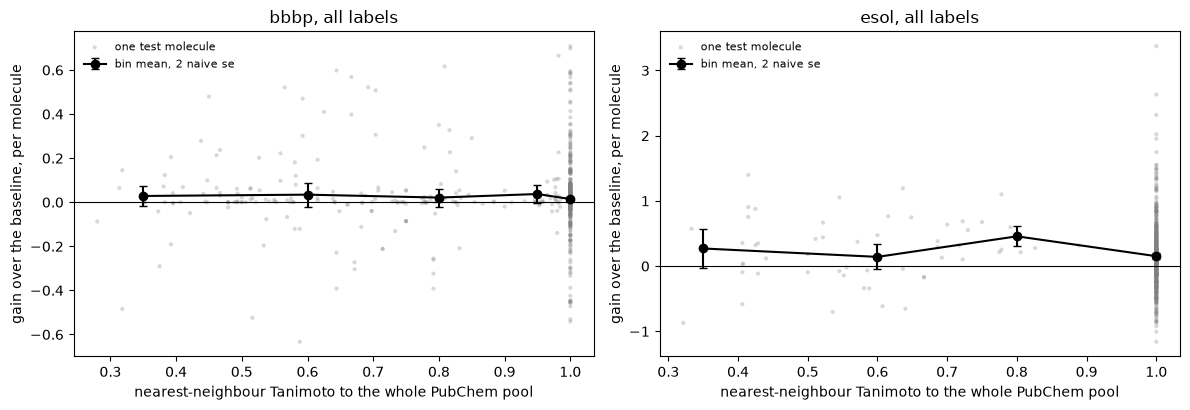

Bins are for reading, not for testing. The estimate is the slope above,
which uses the similarity as it is rather than cut into pieces.

The bars are two naive standard errors and are too narrow. They count
every row as independent, and a quarter of these molecules are scored
in more than one split, by models that share a split. The slope above
clusters on the molecule, which is why it is the number to read.


In [9]:
if ready(STAGE_B, ["per_molecule_gain.csv"]):
    import matplotlib.pyplot as plt

    gains = pd.read_csv(STAGE_B / "per_molecule_gain.csv")
    full = gains[gains.label_count.isna()] if gains.label_count.isna().any() else gains
    tasks = sorted(full.task.unique())
    fig, axes = plt.subplots(1, len(tasks), figsize=(6 * len(tasks), 4.2), squeeze=False)
    for ax, task in zip(axes[0], tasks, strict=True):
        cell = full[full.task == task]
        ax.axhline(0, color="black", linewidth=0.8)
        ax.scatter(
            cell.corpus_similarity,
            cell.gain,
            s=9,
            alpha=0.3,
            color="grey",
            edgecolors="none",
            label="one test molecule",
        )
        edges = [0.2, 0.5, 0.7, 0.9, 0.9999, 1.01]
        mids, means, errs = [], [], []
        for lo, hi in zip(edges[:-1], edges[1:], strict=True):
            band = cell[(cell.corpus_similarity >= lo) & (cell.corpus_similarity < hi)]
            if len(band) >= 10:
                mids.append((lo + min(hi, 1.0)) / 2)
                means.append(band.gain.mean())
                errs.append(1.96 * band.gain.std() / np.sqrt(len(band)))
        ax.errorbar(
            mids, means, yerr=errs, fmt="o-", color="black", capsize=3, label="bin mean, 2 naive se"
        )
        ax.set_xlabel("nearest-neighbour Tanimoto to the whole PubChem pool")
        ax.set_ylabel("gain over the baseline, per molecule")
        ax.set_title(f"{task}, all labels")
        ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    plt.show()
    print("Bins are for reading, not for testing. The estimate is the slope above,")
    print("which uses the similarity as it is rather than cut into pieces.")
    print()
    print("The bars are two naive standard errors and are too narrow. They count")
    print("every row as independent, and a quarter of these molecules are scored")
    print("in more than one split, by models that share a split. The slope above")
    print("clusters on the molecule, which is why it is the number to read.")

## 6. The control that is not a substitute

A molecule's distance to the **pretraining corpus** is not its distance to the
**labelled training set**. Yuxin's point was that the two do not track each
other, and on these splits they do not even have the same shape. The corpus
axis sits at its ceiling for four molecules in five. The training-set axis has
almost no ties at all, and it moves with the label budget: at all labels its
median is around 0.5, and at fifty labels it falls to roughly 0.3, because the
cell really did train on fifty molecules.

That movement is the point of measuring it per budget rather than once over the
whole eighty percent split. A cell that trains on fifty molecules is not close
to the other 1,581.

So the training-set axis has the variation the corpus axis lacks. That is
exactly why it cannot stand in for it. A slope against it answers how far a
model generalises from its labels, which is a different question and a real
one. It is reported beside the primary axis, never in place of it.


In [10]:
if ready(STAGE_B, ["per_molecule_gain.csv"]):
    # Per task and at one label budget. Pooling them would average over
    # budgets whose training-set distances differ by a long way, which hides
    # the comparison rather than making it.
    for task, block in gains.groupby("task"):
        full = block[block.label_count.isna()]
        both = full[["corpus_similarity", "train_similarity"]].dropna()
        if len(both) < 30:
            continue
        print(f"--- {task}, all labels, n={len(both)} ---")
        print(both.describe().loc[["min", "25%", "50%", "75%", "max"]].round(3).to_string())
        print(f"Spearman between the two axes: {both.corr(method='spearman').iloc[0, 1]:+.3f}\n")
    print("Near zero would mean they are different quantities. High would mean the")
    print("control is a restatement of the primary axis and settles nothing.")

--- bbbp, all labels, n=1025 ---
     corpus_similarity  train_similarity
min               0.28             0.108
25%               1.00             0.356
50%               1.00             0.492
75%               1.00             0.629
max               1.00             1.000
Spearman between the two axes: -0.014

--- esol, all labels, n=570 ---
     corpus_similarity  train_similarity
min              0.321             0.155
25%              1.000             0.304
50%              1.000             0.420
75%              1.000             0.510
max              1.000             1.000
Spearman between the two axes: +0.186

Near zero would mean they are different quantities. High would mean the
control is a restatement of the primary axis and settles nothing.


## 7. What the runs say

Two hundred cells. Five arms, two tasks, five scaffold splits, four label
budgets. Every cell on the same laptop CPU, one commit across all of them, one
split fingerprint per task, and not one of the 160 neural cells reached the
200-epoch cap. The numbers below are the whole matrix and not a slice of it.

### Pretraining helps, and how much depends on the task

Against the untrained control of the same architecture, paired by split, 95
percent intervals over five splits.

| budget | BBBP, AUROC | ESOL, RMSE |
|---|---|---|
| 50 | -0.007 [-0.350, 0.336] | **-0.724 [-0.903, -0.545]** |
| 100 | 0.197 [-0.018, 0.412] | **-0.623 [-1.125, -0.121]** |
| 500 | 0.020 [-0.005, 0.046] | **-0.230 [-0.345, -0.115]** |
| all | **0.025 [0.015, 0.034]** | **-0.228 [-0.439, -0.018]** |

Higher is better for AUROC and lower for RMSE, so bold means the interval
clears zero in favour of the pretrained encoder.

On BBBP the benefit only separates from zero at the full budget, and it is
small, two and a half points of AUROC. At 100 labels the point estimate is
eight times larger and the interval is wider than the effect, which is a way of
saying we measured nothing. On ESOL the benefit is there at every budget and it
is big, 0.72 RMSE at fifty labels.

The same checkpoint behaves very differently on the two tasks. We do not have
an explanation we would defend. ESOL is regression and smaller, BBBP is
classification and closer to its ceiling, and either could be doing the work.

### The primary question comes back null

Does the benefit grow with similarity to the pretraining corpus? The primary
cell is BBBP at the full budget, corpus similarity, label-adjusted, clustered on
the molecule.

| task | slope | 95 percent interval | p_im, diagnostic |
|---|---|---|---|
| bbbp, all labels, primary | 0.024 | [-0.050, 0.098] | 0.88 |
| esol, all labels | -0.177 | [-0.589, 0.234] | 0.34 |

The inference is the interval, clustered on the molecule. It covers zero with
room either side on both tasks. 4,100 paired molecule-cells on BBBP over 807
molecules, 699 effective clusters.

`p_im` is a diagnostic and not the test of record, which is a demotion made in
Amendment 15. A quarter of the test molecules appear in more than one split, so
the five per-split slopes it averages are correlated and it errs towards
rejecting. It does not reject here, which is the direction that makes the null
safe rather than fragile.

Read this as no detected association, not as a demonstration that none exists.
The interval still admits a slope of 0.1 in Brier units per unit of similarity,
which would not be nothing.

Pretraining helps. It does not appear to help more where the molecule looks
like what was pretrained on.

One exploratory cell goes the other way, ESOL at a hundred labels, slope 1.18
with an interval of 0.45 to 1.92 and p_im 0.046. It is one of thirty-two
exploratory cells with no multiplicity correction, and the same axis sits near
zero at five hundred labels and turns negative at the full budget. A slope that
changes sign across budgets is noise wearing a result's clothes.

### Two things we were not looking for

**The forest wins where labels are scarce.** On BBBP at fifty labels the random
forest on Morgan fingerprints scores 0.824 against released at 0.686 and
chemprop at 0.453. It beats the untrained control by 0.131 with an interval of
0.046 to 0.216. Plain chemprop at its own settings lands *below* the untrained
control there, -0.240. Whatever pretraining buys at fifty labels, a classical
baseline buys more of it for less.

**Pretraining converges faster.** Mean epochs to early stopping:

| task | released | scratch |
|---|---|---|
| bbbp | 15.8 | 21.6 |
| esol | 19.1 | 28.4 |

Nothing in the protocol was set up to test this, so it is an observation and
not a result. It is also the cheapest benefit in the table to verify again.


## 8. What this does not establish

Written here rather than left implied.

**Corpus membership is not verified pretraining exposure.** `in_pool` means the
structure appears in the published PubChem file. CheMeleon's reference
pretrainer splits that file 70/20/10, so a member was trained on with
probability about 0.7 and held out with probability 0.1. The primary slope does
not use this column. The exposed-against-unexposed contrast does, and it is
exploratory. Amendment 15 has the reconstruction and what it changed, which on
BBBP was nothing.

**No causal claim.** Nobody assigned molecules to be near or far from PubChem.
A molecule that a 944,286-molecule draw happens to miss is unusual in ways that
may predict its error by themselves, so the exposed-against-unexposed contrast
carries a confound it cannot remove. It sits beside the slope, not in place of
it.

**ESOL is poorly determined on the corpus axis.** Fifty-four of its 570 test
observations sit off the similarity ceiling. Section 2 called that fatal before
the runs, which was too strong. The realised interval is wide, not absent, and
a wide interval is an inconclusive result rather than a question the data
cannot touch. Read the ESOL slopes as badly measured, not as answers.

**Exposure is not label leakage.** The checkpoint saw those structures with no
labels attached, which is what CheMeleon did, and Stage C compares against
CheMeleon. The frozen splits make train and test disjoint by construction, and
the pretraining objective never touches a benchmark label.

**This is fine-tuning, not the linear probe.** The probe in `runs/probe` freezes
the encoder and understates what pretraining bought. The two sets of numbers are
not interchangeable and `evaluate.py` refuses to pool them.

**One split protocol.** Scaffold only here. The protocol allows time and random
splits and the published evidence says the split moves a score roughly ten times
more than the method does, so a scaffold-only result is a scaffold-only result.

**Acyclic molecules are never scored.** They share the empty Murcko scaffold and
land in one group, which the balanced rule places outside test in every seed. An
ESOL number is a statement about ring-containing ESOL.